# Ellipsoid - Full Dimensionality (D = d)
f(x) = sum_i lambda_i (x_i - 1)^2, lambda = geomspace(1, 100, D)
Configs: D = d = 2, 5, 10, 20 | Algorithms: GP-BO (EI), CMA-ES | Seeds 0-4 | 100 evals/run
Total: 4 x 2 x 5 = 40 runs.

In [ ]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import norm, qmc
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel, WhiteKernel
import cma

warnings.filterwarnings("ignore")

CONFIG = dict(
    experiment="E1",
    function="Ellipsoid",
    configs=[(2, 2), (5, 5), (10, 10), (20, 20)],   # (D, d)
    seeds=[0, 1, 2, 3, 4],
    budget=100,                  # objective evaluations per run (includes initial points)
    lower=-5.0, upper=5.0,
    optimum_value=1.0,           # relevant coordinates optimum
    weight_min=1.0, weight_max=100.0,
    # --- BO settings ---
    bo_kernel="Matern(nu=2.5) isotropic + constant + white noise(1e-6..1e-2)",
    bo_n_init=10,                # Sobol initial design, counted toward budget
    bo_acq="EI (xi=0.0), minimisation",
    bo_n_random_candidates=2000,
    bo_n_local_candidates=500,   # Gaussian perturbations around incumbent (sd=0.1 in unit cube)
    # --- CMA-ES settings ---
    cma_x0="centre of box (0,...,0)",
    cma_sigma0=2.5,              # 1/4 of the range
    cma_popsize="default (4 + floor(3 ln D))",
    cma_boundary="cma BoundTransform (bounds option)",
    cma_incomplete_generation="stop mid-generation: only evaluate as many candidates as budget allows",
    cma_seed_offset=1,           # cma treats seed=0 as 'random'; so use seed + 1
)

SAVE_FILES = False
OUT_DIR = Path.cwd()

In [4]:
def make_ellipsoid(D, d=None, lo=1.0, hi=100.0, opt=1.0):
    """Ellipsoid on D inputs using the first d coordinates (d=D for full dimensionality)."""
    d = D if d is None else d
    lam = np.geomspace(lo, hi, d)

    def f(x):
        x = np.asarray(x, dtype=float)
        assert x.shape[-1] == D, f"expected {D} inputs, got {x.shape}"
        return float(np.sum(lam * (x[:d] - opt) ** 2))

    f.lam, f.D, f.d = lam, D, d
    return f


def test_objectives():
    for D, d in CONFIG["configs"]:
        f = make_ellipsoid(D, d)
        lam = f.lam
        assert np.isclose(lam[0], 1.0) and np.isclose(lam[-1], 100.0), "weight endpoints wrong"
        assert np.isclose(lam[-1] / lam[0], 100.0), "condition number should be 100"
        assert f(np.ones(D)) == 0.0, "optimum should be 0"
        x = np.full(D, 1.0); x[0] = 2.0
        assert np.isclose(f(x), lam[0]), "single-coordinate check failed"
        assert np.all(np.diff(lam) > 0), "weights should increase"
        # geometric spacing: constant ratio
        if D > 2:
            ratios = lam[1:] / lam[:-1]
            assert np.allclose(ratios, ratios[0]), "weights not geometric"
        print(f"OK  D={D:2d} d={d:2d}  weights {lam[0]:.1f}..{lam[-1]:.1f}  cond={lam[-1]/lam[0]:.0f}  f(opt)=0")
    print("All objective tests passed.\n")

test_objectives()

OK  D= 2 d= 2  weights 1.0..100.0  cond=100  f(opt)=0
OK  D= 5 d= 5  weights 1.0..100.0  cond=100  f(opt)=0
OK  D=10 d=10  weights 1.0..100.0  cond=100  f(opt)=0
OK  D=20 d=20  weights 1.0..100.0  cond=100  f(opt)=0
All objective tests passed.



In [5]:
def run_bo(f, D, seed, budget, lo, hi, cfg):
    rng = np.random.default_rng(seed)
    n_init = min(cfg["bo_n_init"], budget)
    sob = qmc.Sobol(d=D, scramble=True, seed=seed)
    U = sob.random(n_init)                                  # unit-cube points
    to_x = lambda u: lo + (hi - lo) * np.asarray(u)
    X_u, y = [], []
    for u in U:
        X_u.append(u); y.append(f(to_x(u)))

    kernel = (ConstantKernel(1.0, (1e-2, 1e2))
              * Matern(length_scale=0.3, length_scale_bounds=(1e-2, 1e1), nu=2.5)
              + WhiteKernel(1e-4, (1e-6, 1e-2)))

    while len(y) < budget:
        Xa, ya = np.array(X_u), np.array(y)
        mu_y, sd_y = ya.mean(), ya.std() + 1e-12
        z = (ya - mu_y) / sd_y
        gp = GaussianProcessRegressor(kernel=kernel, normalize_y=False,
                                      n_restarts_optimizer=0, random_state=seed)
        gp.fit(Xa, z)

        best_u = Xa[np.argmin(ya)]
        cand = rng.random((cfg["bo_n_random_candidates"], D))
        local = np.clip(best_u + 0.1 * rng.standard_normal((cfg["bo_n_local_candidates"], D)), 0, 1)
        cand = np.vstack([cand, local])

        mu, sd = gp.predict(cand, return_std=True)
        sd = np.maximum(sd, 1e-12)
        imp = z.min() - mu
        zz = imp / sd
        ei = imp * norm.cdf(zz) + sd * norm.pdf(zz)
        u_next = cand[np.argmax(ei)]

        X_u.append(u_next); y.append(f(to_x(u_next)))

    X = np.array([to_x(u) for u in X_u])
    return X, np.array(y), "budget_reached"

In [6]:
def run_cma(f, D, seed, budget, lo, hi, cfg):
    es = cma.CMAEvolutionStrategy(
        np.zeros(D), cfg["cma_sigma0"],
        {"bounds": [lo, hi], "seed": seed + cfg["cma_seed_offset"],
         "verbose": -9, "maxfevals": 10**9, "tolfun": 0, "tolx": 0, "tolstagnation": 10**9},
    )
    X, y = [], []
    reason = "budget_reached"
    while len(y) < budget:
        if es.stop() and set(es.stop().keys()) - {"maxfevals"}:
            reason = "cma_stop:" + ",".join(es.stop().keys()); break
        sols = es.ask()
        remaining = budget - len(y)
        evaluated = sols[:remaining]                         # truncate incomplete final generation
        vals = [f(s) for s in evaluated]
        X.extend(evaluated); y.extend(vals)
        if len(evaluated) < len(sols):
            reason = "budget_reached_mid_generation"; break  # no tell(): generation incomplete
        es.tell(sols, vals)
    return np.array(X), np.array(y), reason


RUNNERS = {"BO": run_bo, "CMA-ES": run_cma}

In [7]:
def run_all():
    rows, xrecs, summary = [], [], []
    total = len(CONFIG["configs"]) * len(RUNNERS) * len(CONFIG["seeds"])
    k = 0
    for D, d in CONFIG["configs"]:
        f = make_ellipsoid(D, d, CONFIG["weight_min"], CONFIG["weight_max"], CONFIG["optimum_value"])
        for algo, runner in RUNNERS.items():
            for seed in CONFIG["seeds"]:
                k += 1
                t0 = time.perf_counter()
                X = y = None
                try:
                    X, y, reason = runner(f, D, seed, CONFIG["budget"],
                                          CONFIG["lower"], CONFIG["upper"], CONFIG)
                except Exception as e:                       # keep whatever we have
                    reason = f"error:{type(e).__name__}:{e}"
                    print("  !!", reason)
                elapsed = time.perf_counter() - t0

                if y is not None and len(y) > 0:
                    best = np.minimum.accumulate(y)
                    for i, (yi, bi) in enumerate(zip(y, best), start=1):
                        rows.append(dict(experiment=CONFIG["experiment"], function="Ellipsoid",
                                         algorithm=algo, D=D, d=d, seed=seed, evaluation=i,
                                         objective_value=float(yi), best_value=float(bi),
                                         elapsed_seconds=elapsed))
                    xrecs.append(dict(algorithm=algo, D=D, d=d, seed=seed,
                                      X=np.asarray(X).tolist()))
                n_eval = 0 if y is None else len(y)
                summary.append(dict(experiment=CONFIG["experiment"], function="Ellipsoid",
                                    algorithm=algo, D=D, d=d, seed=seed,
                                    actual_evaluations=n_eval,
                                    final_best=None if n_eval == 0 else float(np.min(y)),
                                    elapsed_seconds=elapsed, termination_reason=reason))
                print(f"[{k:2d}/{total}] {algo:6s} D={D:2d} seed={seed}  "
                      f"evals={n_eval:3d}  best={summary[-1]['final_best']}  {elapsed:.1f}s  ({reason})")

                if SAVE_FILES:
                    pd.DataFrame(rows).to_csv(OUT_DIR / "person2_evaluations.csv", index=False)
                    pd.DataFrame(summary).to_csv(OUT_DIR / "person2_runs_summary.csv", index=False)
                    with open(OUT_DIR / "person2_x_vectors.json", "w") as fh:
                        json.dump(xrecs, fh)

    if SAVE_FILES:
        with open(OUT_DIR / "person2_metadata.json", "w") as fh:
            json.dump(CONFIG, fh, indent=2, default=str)
    return pd.DataFrame(rows), pd.DataFrame(summary), xrecs


evals, summary, xrecs = run_all()

[ 1/40] BO     D= 2 seed=0  evals=100  best=0.00011913696914171064  0.6s  (budget_reached)
[ 2/40] BO     D= 2 seed=1  evals=100  best=0.0008192935494785247  0.6s  (budget_reached)
[ 3/40] BO     D= 2 seed=2  evals=100  best=5.009439693072148e-05  0.4s  (budget_reached)
[ 4/40] BO     D= 2 seed=3  evals=100  best=1.548489141320787e-05  0.5s  (budget_reached)
[ 5/40] BO     D= 2 seed=4  evals=100  best=0.0005660418522394209  0.6s  (budget_reached)
[ 6/40] CMA-ES D= 2 seed=0  evals=100  best=0.0002413486855318214  0.0s  (budget_reached_mid_generation)
[ 7/40] CMA-ES D= 2 seed=1  evals=100  best=0.014902354720048146  0.0s  (budget_reached_mid_generation)
[ 8/40] CMA-ES D= 2 seed=2  evals=100  best=0.29314981674060764  0.0s  (budget_reached_mid_generation)
[ 9/40] CMA-ES D= 2 seed=3  evals=100  best=0.019951748068664822  0.0s  (budget_reached_mid_generation)
[10/40] CMA-ES D= 2 seed=4  evals=100  best=0.011695402853679416  0.0s  (budget_reached_mid_generation)
[11/40] BO     D= 5 seed=0  e

In [8]:
expected = len(CONFIG["configs"]) * len(RUNNERS) * len(CONFIG["seeds"])
print(f"\nRuns completed: {len(summary)} / {expected}")
bad = summary[summary.actual_evaluations != CONFIG["budget"]]
print("Runs not at exactly", CONFIG["budget"], "evaluations:", len(bad))
if len(bad):
    print(bad)


Runs completed: 40 / 40
Runs not at exactly 100 evaluations: 0



Final best value after 100 evaluations (over 5 seeds):


median      mean       std       min       max
D  algorithm                                                  
2  BO           0.0001    0.0003    0.0004    0.0000    0.0008
   CMA-ES       0.0149    0.0680    0.1261    0.0002    0.2931
5  BO           0.7893    0.7389    0.2312    0.4074    0.9803
   CMA-ES       7.1254   23.7675   38.2403    2.5376   91.9176
10 BO          24.6988   27.2810   10.8940   13.5283   43.2077
   CMA-ES     141.5505  150.1758   53.8410   83.8227  224.1557
20 BO         284.9000  368.4955  180.1206  225.5345  665.8099
   CMA-ES     700.6138  626.1698  133.0138  437.1662  741.9250


Per-run summary:


,experiment,function,algorithm,D,d,seed,actual_evaluations,final_best,elapsed_seconds,termination_reason
0,E1,Ellipsoid,BO,2,2,0,100,0.000119,0.612789,budget_reached
1,E1,Ellipsoid,BO,2,2,1,100,0.000819,0.564437,budget_reached
2,E1,Ellipsoid,BO,2,2,2,100,0.000050,0.446969,budget_reached
3,E1,Ellipsoid,BO,2,2,3,100,0.000015,0.461068,budget_reached
4,E1,Ellipsoid,BO,2,2,4,100,0.000566,0.645470,budget_reached
5,E1,Ellipsoid,CMA-ES,2,2,0,100,0.000241,0.007109,budget_reached_mid_generation
6,E1,Ellipsoid,CMA-ES,2,2,1,100,0.014902,0.003827,budget_reached_mid_generation
7,E1,Ellipsoid,CMA-ES,2,2,2,100,0.293150,0.003814,budget_reached_mid_generation
8,E1,Ellipsoid,CMA-ES,2,2,3,100,0.019952,0.003456,budget_reached_mid_generation
9,E1,Ellipsoid,CMA-ES,2,2,4,100,0.011695,0.003503,budget_reached_mid_generation



First rows of the evaluation-level results:


,experiment,function,algorithm,D,d,seed,evaluation,objective_value,best_value,elapsed_seconds
0,E1,Ellipsoid,BO,2,2,0,1,1104.313600,1104.313600,0.612789
1,E1,Ellipsoid,BO,2,2,0,2,1877.639294,1104.313600,0.612789
2,E1,Ellipsoid,BO,2,2,0,3,13.036656,13.036656,0.612789
3,E1,Ellipsoid,BO,2,2,0,4,746.801255,13.036656,0.612789
4,E1,Ellipsoid,BO,2,2,0,5,124.481588,13.036656,0.612789
5,E1,Ellipsoid,BO,2,2,0,6,263.825921,13.036656,0.612789
6,E1,Ellipsoid,BO,2,2,0,7,443.741835,13.036656,0.612789
7,E1,Ellipsoid,BO,2,2,0,8,3075.107392,13.036656,0.612789
8,E1,Ellipsoid,BO,2,2,0,9,96.333616,13.036656,0.612789
9,E1,Ellipsoid,BO,2,2,0,10,1065.093087,13.036656,0.612789


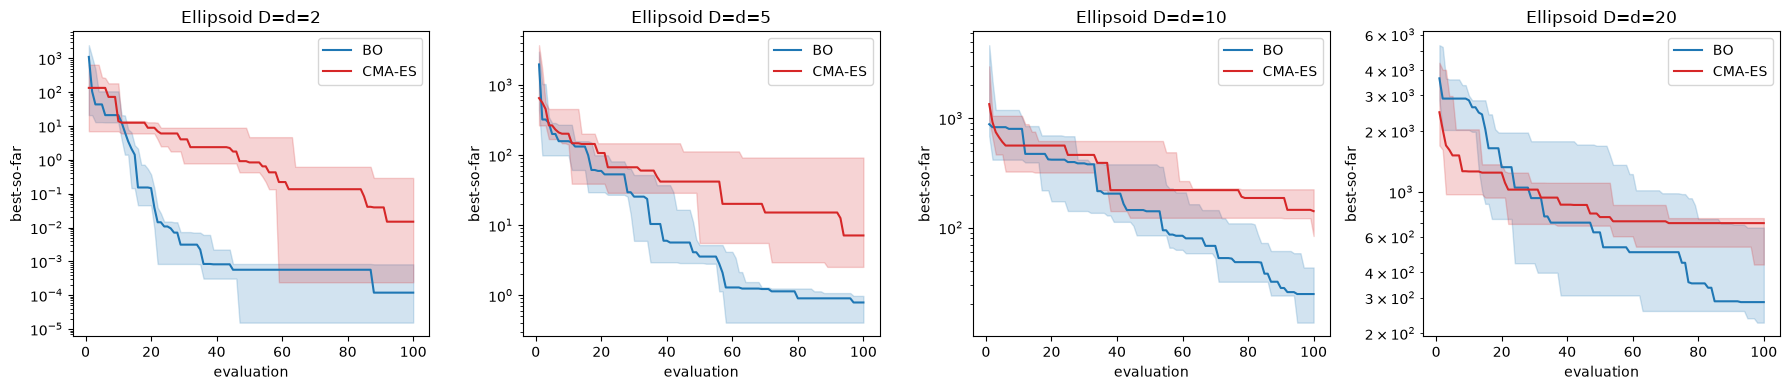

In [9]:
tab = (summary.groupby(["D", "algorithm"])["final_best"]
       .agg(["median", "mean", "std", "min", "max"]).round(4))
print("\nFinal best value after 100 evaluations (over 5 seeds):")
display(tab)
print("\nPer-run summary:")
display(summary)
print("\nFirst rows of the evaluation-level results:")
display(evals.head(10))
if SAVE_FILES:
    tab.to_csv(OUT_DIR / "person2_final_best_table.csv")

try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=False)
    for ax, (D, d) in zip(axes, CONFIG["configs"]):
        for algo, c in [("BO", "tab:blue"), ("CMA-ES", "tab:red")]:
            sub = evals[(evals.D == D) & (evals.algorithm == algo)]
            piv = sub.pivot(index="evaluation", columns="seed", values="best_value")
            ax.plot(piv.index, piv.median(axis=1), color=c, label=algo)
            ax.fill_between(piv.index, piv.min(axis=1), piv.max(axis=1), color=c, alpha=0.2)
        ax.set_yscale("log"); ax.set_title(f"Ellipsoid D=d={D}")
        ax.set_xlabel("evaluation"); ax.set_ylabel("best-so-far"); ax.legend()
    plt.tight_layout()
    if SAVE_FILES:
        plt.savefig(OUT_DIR / "person2_convergence.png", dpi=150)
    plt.show()
except Exception as e:
    print("Plot skipped:", e)

In [10]:
#Cell 1 — Run experiments with different budgets
# EXPERIMENT 1: BUDGET SENSITIVITY

BUDGETS = [100, 250, 500]
DIMENSIONS = [5, 10, 20]
SEEDS = [0, 1, 2, 3, 4]

budget_results = []
budget_curves = []

for D in DIMENSIONS:
    f = make_ellipsoid(D, D)

    for budget in BUDGETS:
        for algo, runner in RUNNERS.items():
            for seed in SEEDS:

                start = time.perf_counter()

                X, y, reason = runner(
                    f, D, seed, budget,
                    CONFIG["lower"],
                    CONFIG["upper"],
                    CONFIG
                )

                elapsed = time.perf_counter() - start
                best = np.minimum.accumulate(y)

                budget_results.append({
                    "D": D,
                    "budget": budget,
                    "algorithm": algo,
                    "seed": seed,
                    "final_best": best[-1],
                    "runtime": elapsed,
                    "evaluations": len(y),
                    "reason": reason
                })

                for i, value in enumerate(best, start=1):
                    budget_curves.append({
                        "D": D,
                        "budget": budget,
                        "algorithm": algo,
                        "seed": seed,
                        "evaluation": i,
                        "best_value": value
                    })

                print(
                    f"D={D}, Budget={budget}, "
                    f"{algo}, Seed={seed}, "
                    f"Best={best[-1]:.4f}"
                )

budget_df = pd.DataFrame(budget_results)
curves_df = pd.DataFrame(budget_curves)

display(budget_df.head())

D=5, Budget=100, BO, Seed=0, Best=0.9041
D=5, Budget=100, BO, Seed=1, Best=0.9803
D=5, Budget=100, BO, Seed=2, Best=0.4074
D=5, Budget=100, BO, Seed=3, Best=0.6134
D=5, Budget=100, BO, Seed=4, Best=0.7893
D=5, Budget=100, CMA-ES, Seed=0, Best=7.1254
D=5, Budget=100, CMA-ES, Seed=1, Best=11.6946
D=5, Budget=100, CMA-ES, Seed=2, Best=91.9176
D=5, Budget=100, CMA-ES, Seed=3, Best=2.5376
D=5, Budget=100, CMA-ES, Seed=4, Best=5.5624
D=5, Budget=250, BO, Seed=0, Best=0.4624
D=5, Budget=250, BO, Seed=1, Best=0.2099
D=5, Budget=250, BO, Seed=2, Best=0.3564
D=5, Budget=250, BO, Seed=3, Best=0.1909
D=5, Budget=250, BO, Seed=4, Best=0.1673
D=5, Budget=250, CMA-ES, Seed=0, Best=0.1285
D=5, Budget=250, CMA-ES, Seed=1, Best=0.7359
D=5, Budget=250, CMA-ES, Seed=2, Best=7.5636
D=5, Budget=250, CMA-ES, Seed=3, Best=0.0483
D=5, Budget=250, CMA-ES, Seed=4, Best=0.0959
D=5, Budget=500, BO, Seed=0, Best=0.3006
D=5, Budget=500, BO, Seed=1, Best=0.2099
D=5, Budget=500, BO, Seed=2, Best=0.2912
D=5, Budget=500

,D,budget,algorithm,seed,final_best,runtime,evaluations,reason
0,5,100,BO,0,0.904060,1.074324,100,budget_reached
1,5,100,BO,1,0.980332,0.906016,100,budget_reached
2,5,100,BO,2,0.407395,0.864387,100,budget_reached
3,5,100,BO,3,0.613368,0.945590,100,budget_reached
4,5,100,BO,4,0.789327,0.819053,100,budget_reached


In [11]:
budget_summary = (
    budget_df
    .groupby(["D", "budget", "algorithm"])
    .agg(
        median_best=("final_best", "median"),
        mean_best=("final_best", "mean"),
        std_best=("final_best", "std"),
        median_runtime=("runtime", "median")
    )
    .round(4)
    .reset_index()
)

display(budget_summary)

,D,budget,algorithm,median_best,mean_best,std_best,median_runtime
0,5,100,BO,0.7893,0.7389,0.2312,0.9060
1,5,100,CMA-ES,7.1254,23.7675,38.2403,0.0041
2,5,250,BO,0.2099,0.2774,0.1271,6.0010
3,5,250,CMA-ES,0.1285,1.7145,3.2818,0.0129
4,5,500,BO,0.2099,0.2320,0.0603,45.8189
5,5,500,CMA-ES,0.0000,0.0018,0.0037,0.0338
6,10,100,BO,24.6988,27.2810,10.8940,1.1546
7,10,100,CMA-ES,141.5505,150.1758,53.8410,0.0036
8,10,250,BO,6.3719,5.9111,1.9712,12.1150
9,10,250,CMA-ES,24.4063,25.7893,5.7917,0.0176


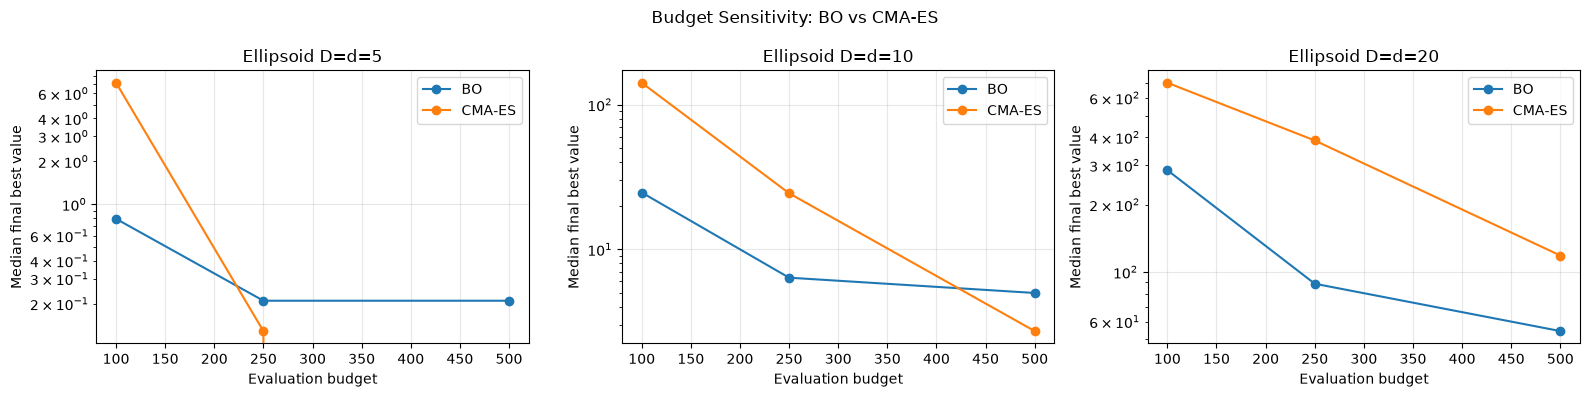

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, D in zip(axes, DIMENSIONS):

    for algo in ["BO", "CMA-ES"]:

        sub = budget_summary[
            (budget_summary["D"] == D) &
            (budget_summary["algorithm"] == algo)
        ].sort_values("budget")

        ax.plot(
            sub["budget"],
            sub["median_best"],
            marker="o",
            label=algo
        )

    ax.set_title(f"Ellipsoid D=d={D}")
    ax.set_xlabel("Evaluation budget")
    ax.set_ylabel("Median final best value")
    ax.set_yscale("log")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Budget Sensitivity: BO vs CMA-ES")
plt.tight_layout()
plt.show()

In [13]:
comparison = budget_summary.pivot(
    index=["D", "budget"],
    columns="algorithm",
    values="median_best"
).reset_index()

comparison["CMA_to_BO_ratio"] = (
    comparison["CMA-ES"] / comparison["BO"]
)

display(comparison.round(4))

algorithm,D,budget,BO,CMA-ES,CMA_to_BO_ratio
0,5,100,0.7893,7.1254,9.0275
1,5,250,0.2099,0.1285,0.6122
2,5,500,0.2099,0.0000,0.0000
3,10,100,24.6988,141.5505,5.7311
4,10,250,6.3719,24.4063,3.8303
5,10,500,4.9961,2.7251,0.5454
6,20,100,284.9000,700.6138,2.4592
7,20,250,88.5833,386.8599,4.3672
8,20,500,54.4127,118.3960,2.1759
